# From a frozen plume to native camera reads

This notebook explains the current scope of [`support/spatial_scene.py`](support/spatial_scene.py). Start with its prescribed atmosphere and gas cloud, compare two direct-solar path treatments, then follow radiance into eight native camera reads and their sensitivities.

Run the cells in order. The cells use flat chart-local queries; saved outputs come from the current model-method execution. All physical inputs are synthetic and local; execution requires the provisioned Orsia environment with NumPy, SciPy, Matplotlib and Jupyter. The [execution guide](README.md#spatial-scene) gives the command. Saved results demonstrate this numerical composition; they do not qualify a physical atmosphere, retrieval or instrument.

The support module owns fixture choices and binds reusable operations. `orsia_scene` composes gas amounts and radiance; Geometry owns paths and frames, Dispersion owns Gaussian integrals, Radiative owns transfer, and Instruments owns acquisition and detector response. The [scope guide](../docs/spatial-scenes.md) documents their contracts.

In [1]:
import io
import sys
from dataclasses import replace
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.patches import Rectangle
from orsia_dispersion import puff_concentration
from orsia_geometry import affine_surface_points, segment_layer_paths
from orsia_radiative import SpectralDomain, clip_atmosphere_height, wavenumber_grid

# Jupyter starts in notebooks/; the isolated test starts at the repository root.
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from notebooks.support import spatial_scene as scene
from notebooks.support.terrain import SplineTerrain

started = perf_counter()
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})


def show_figure(figure):
    """Display inline PNG bytes and close the supplied Matplotlib figure."""
    with io.BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=130)
        display(Image(data=buffer.getvalue()))
    plt.close(figure)


print(f"Python {sys.version.split()[0]}; GIL enabled after imports: {sys._is_gil_enabled()}")

Python 3.14.3; GIL enabled after imports: False


## 1. Inspect the fixture before binding callbacks

`synthetic_inputs()` returns fresh inputs. Edit a fresh dictionary before constructing `SyntheticRadianceModel` or calling `make_acquisition`; keep its arrays and values stable while the bound callbacks are used.

| Input | Default and meaning |
| --- | --- |
| `background` | Interfaces `[0, 500, 1500] m`; pressure interfaces `[100000, 90000, 70000] Pa`; layer temperatures `[290, 280] K`. Dry-air density is `2e25 molecules/m³`; water/dry-air ratio is `0.01`; CH4-labelled dry-air fraction is `2e-6`. |
| `plume` | One free-space Gaussian: mass `20 kg`, centre `(150, 0, 800) m`, standard deviations `(180, 200, 120) m`. Covariance entries have units m². |
| `molar_mass_kg_mol` | `0.01604 kg/mol`; path mass in kg/m² is converted to molecules/m² using the Avogadro constant divided by molar mass. |
| Terrain | `z = height_m + slopes[0]*x + slopes[1]*y`; default height `250 m`, dimensionless slopes `(0, 0)`. All positions share one Cartesian vertical datum. |
| Support | Chart x and y each in `[-3000, 3000] m`; wavenumber in `[4000, 4100] cm⁻¹`; elapsed time in `[0, 0.3] s`. |
| Frame | UTC epoch `2023-05-16T00:00:00Z`; synthetic chart-to-GCRS rotation at `0.02 rad/s`. GCRS (Geocentric Celestial Reference System) is the observation frame used by the camera interface. |

The cloud stays frozen at elapsed time zero. Query time changes the frame conversion and camera location; the support module calls no wind, diffusivity or transport update. The [dispersion tutorial](gaussian_puff_dispersion.ipynb) covers transport separately.

In [2]:
inputs = scene.synthetic_inputs()
plume = inputs["plume"]
background = inputs["background"]
retained = clip_atmosphere_height(background, inputs["height_m"])
excluded_mass_kg = scene.plume_excluded_mass_bound(inputs)
print("Puff mass [kg]:", plume.masses_kg)
print("Puff centre [m]:", plume.centres_m)
print("Retained height interfaces [m]:", retained.height_boundaries_m)
print("Retained background CH4 columns [molecules/m²]:",
      retained.absorbers[0].columns_molecules_m2)
print(f"Excluded prescribed mass upper bound: {excluded_mass_kg:.6g} kg "
      f"({excluded_mass_kg / plume.masses_kg.sum():.3g} of total)")

Puff mass [kg]: [20.]
Puff centre [m]: [[150.   0. 800.]]
Retained height interfaces [m]: [ 250.  500. 1500.]
Retained background CH4 columns [molecules/m²]: [1.e+22 4.e+22]
Excluded prescribed mass upper bound: 4.58165e-05 kg (2.29e-06 of total)


## 2. Locate the cloud and the light paths

The terrain cuts the lower atmospheric layer in half. The clipping call above illustrates retained background columns; `SyntheticRadianceModel` composes molecular amounts on segmented paths. Free-space Gaussian tails outside the terrain/top/horizontal support are excluded without mass renormalization. The printed union bound conservatively accounts for excluded mass; the model applies no terrain-aware transport or reflecting boundary.

The left panel shows a concentration slice at the cloud centre height. The right panel shows a vertical slice through `y = 0`, with paths starting at one surface point. Solar direction points outward toward the Sun; solar photons travel along that path in reverse. View direction points outward toward the sensor above the atmospheric top.

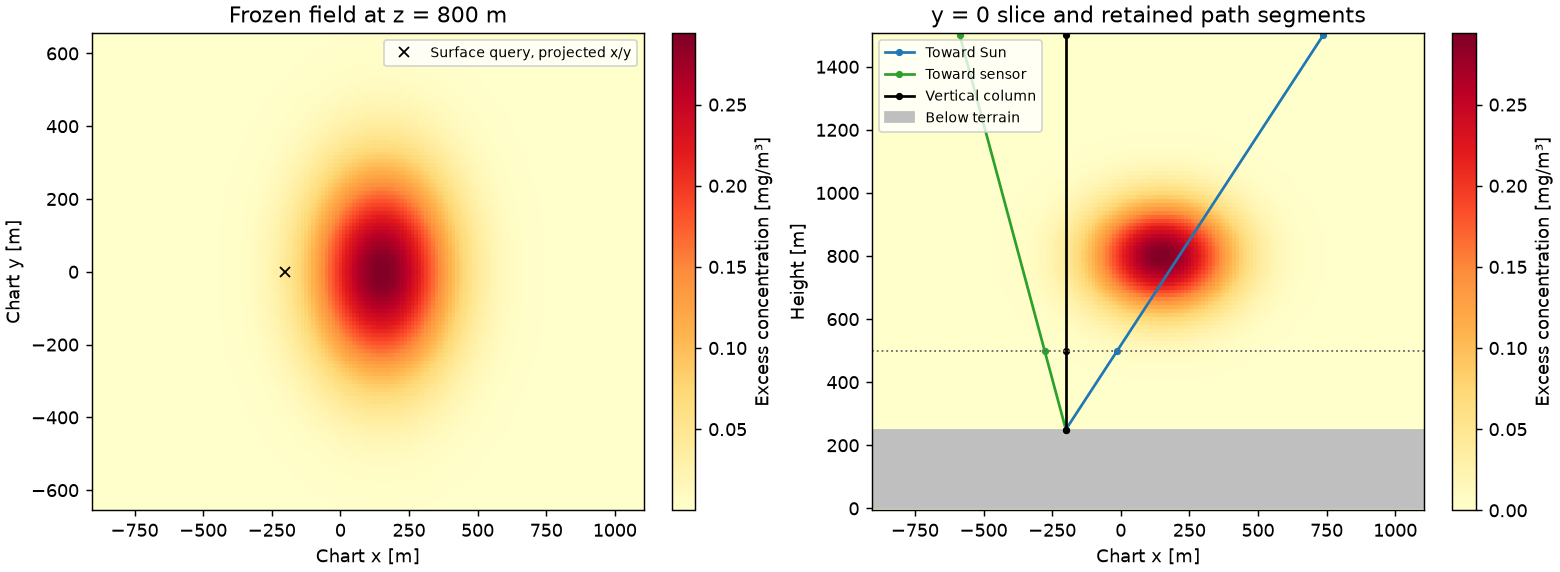

In [3]:
x = np.linspace(-900, 1100, 161)
y = np.linspace(-650, 650, 121)
z = np.linspace(0, 1500, 121)
xx, yy = np.meshgrid(x, y)
xxz, zz = np.meshgrid(x, z)
map_points = np.stack((xx, yy, np.full_like(xx, 800)), axis=-1)
slice_points = np.stack((xxz, np.zeros_like(xxz), zz), axis=-1)
map_concentration = puff_concentration(plume, map_points, boundary="free") * 1e6
slice_concentration = puff_concentration(plume, slice_points, boundary="free") * 1e6
view_local = np.array([-np.sin(0.3), 0.0, np.cos(0.3)])
surface_point, normal = affine_surface_points(
    np.array([[-200.0, 0.0]]), height_m=inputs["height_m"], slopes=inputs["slopes"]
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for ax, horizontal, vertical, values in (
    (axes[0], xx, yy, map_concentration),
    (axes[1], xxz, zz, slice_concentration),
):
    image = ax.pcolormesh(horizontal, vertical, values, shading="auto", cmap="YlOrRd")
    fig.colorbar(image, ax=ax, label="Excess concentration [mg/m³]")
    ax.set_xlabel("Chart x [m]")
axes[0].set(ylabel="Chart y [m]", title="Frozen field at z = 800 m")
axes[0].plot(-200, 0, "kx", label="Surface query, projected x/y")
axes[0].legend(fontsize=8)
for direction, label, color in (
    (inputs["sun_direction"], "Toward Sun", "tab:blue"),
    (view_local, "Toward sensor", "tab:green"),
    (np.array([0.0, 0.0, 1.0]), "Vertical column", "black"),
):
    starts, ends, _, _ = segment_layer_paths(
        surface_point, direction[None, :], background.height_boundaries_m,
        minimum_upward_cosine=0.2,
    )
    path = np.concatenate((starts[:1], ends))
    axes[1].plot(path[:, 0], path[:, 2], "o-", color=color, label=label, markersize=3)
axes[1].axhspan(0, inputs["height_m"], color="0.75", label="Below terrain")
axes[1].axhline(500, color="0.4", linestyle=":", linewidth=1)
axes[1].set(ylabel="Height [m]", title="y = 0 slice and retained path segments")
axes[1].legend(fontsize=8, loc="upper left")
show_figure(fig)

## 3. Supply a synthetic spectral response

`synthetic_cross_section` supplies the same smooth CH4-labelled absorption curve in each layer. The curve has no measured-line provenance and no pressure or temperature dependence. The atmosphere's pressure and temperature values remain fixed context in this example.

The support module also prescribes beam-normal irradiance `E = 0.02 W m⁻² per (cm⁻¹)` and a Lambertian reflectance law:

\[
\rho(x,\tilde\nu) = 0.25 + r + c\tanh(x/150)\,[1+(\tilde\nu-4050)/200].
\]

Here `r` is `reflectance_offset`, `c` is `reflectance_contrast` (default `0.05`), x is in metres, and wavenumber is in cm⁻¹. `SyntheticRadianceModel` checks that reflectance stays in `[0, 1]` across the declared spectral and spatial support.

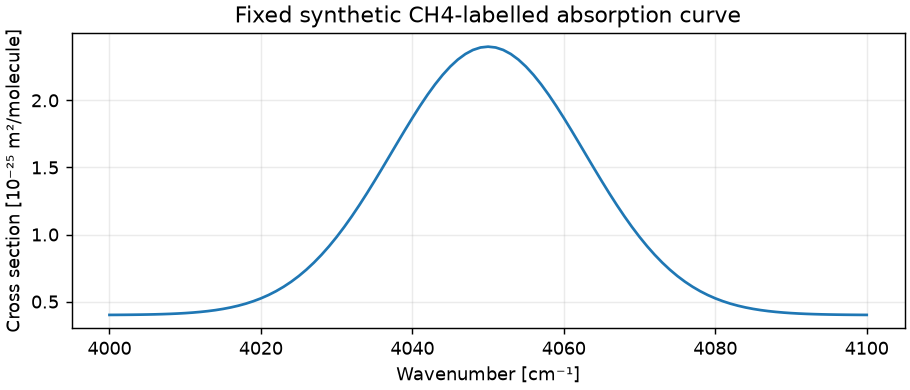

In [4]:
points = np.linspace(*inputs["spectral_interval"], 101)
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.plot(points, scene.synthetic_cross_section(points) / 1e-25)
ax.set(xlabel="Wavenumber [cm⁻¹]", ylabel="Cross section [10⁻²⁵ m²/molecule]",
       title="Fixed synthetic CH4-labelled absorption curve")
ax.grid(alpha=0.25)
show_figure(fig)

## 4. Read the callback boundary: shape, frame and sign

`SyntheticRadianceModel` owns the physical configuration and shared preparation. Its `radiance` and `radiance_tangent` methods both accept `(xy_m, view_local, times_s, spectral)`, with a `SpectralGrid` declaring the cm-1 samples. Positions and outward surface-to-sensor unit views share one chart-fixed Cartesian frame. Geometry preparation converts the scene-directed GCRS rays before physical evaluation.

For the chart-to-GCRS rotation `R(t)`, projection computes `view_local = -R(t).T @ direction_gcrs`. Instruments flattens reads then nodes in C order, calls radiance on flat queries, and restores its integration axes. The example below illustrates the conversion explicitly; the radiance callback receives the resulting local views.

| Quantity | Two-query example | Camera callback |
| --- | --- | --- |
| Chart x/y | `(2,2)` | `(N,2)` |
| Outward local view | `(2,3)` | `(N,3)` |
| Elapsed time | `(2,)` | `(N,)` |
| Spectral nodes | `(5,)` | `(K,)` |
| Radiance | `(2,5)` | `(N,K)` |
| Tangent | `(2,5,2)` | `(N,K,parameter)` |

The final parameter axis is **plume amplitude, then reflectance offset**. The application binding checks sampled time and spectral support. Scene checks spatial and path support; the acquisition certificate later checks complete continuous reads.


In [5]:
# Same chart point and outward direction, at two different times.
query_xy = np.array([[150.0, 0.0], [150.0, 0.0]])
query_times = np.array([0.0, 0.2])
query_views = np.broadcast_to(view_local, (*query_times.shape, 3))
rotations = scene.chart_rotation(query_times, inputs["angular_rate_rad_s"])
query_directions = -np.einsum("...ij,...j->...i", rotations, query_views)
recovered_views = -np.einsum("...ji,...j->...i", rotations, query_directions)
np.testing.assert_allclose(recovered_views, query_views, atol=1e-15)

model = scene.SyntheticRadianceModel(
    mode="heterogeneous_direct_solar", inputs=inputs,
    plume_amplitude=1.0, reflectance_offset=0.0,
)
small_points = np.linspace(*inputs["spectral_interval"], 5)
small_values, small_tangent = model.radiance_tangent(query_xy, recovered_views, query_times, wavenumber_grid(small_points))
np.testing.assert_allclose(small_values[0], small_values[1], rtol=1e-14)
print("Scene-directed observation vectors:\n", query_directions)
print("Recovered outward local vectors:\n", recovered_views)
print("Radiance shape:", small_values.shape, "; tangent shape:", small_tangent.shape)
print("Identical local queries recover identical frozen-field spectra.")

Scene-directed observation vectors:
 [[ 0.29552021 -0.         -0.95533649]
 [ 0.29551784  0.00118208 -0.95533649]]
Recovered outward local vectors:
 [[-2.95520207e-01 -0.00000000e+00  9.55336489e-01]
 [-2.95520207e-01 -9.13095329e-21  9.55336489e-01]]
Radiance shape: (2, 5) ; tangent shape: (2, 5, 2)
Identical local queries recover identical frozen-field spectra.


The direct `radiance` callback calls `orsia_scene.surface_radiance` with an amounts-only plume callback. It computes no tangents. The separate `radiance_tangent` method calls `surface_radiance_tangent` with explicit plume and reflectance seeds. Both branches share physical inputs and sampled-support checks.
The compatibility function `make_callbacks` returns these two bound methods for existing tuple-based callers.


## 5. Compare two treatments of the same field

Both modes compute direct Lambertian reflection with absorption on the incoming and outgoing paths:

\[
L = \rho E\mu/\pi\;\exp(-\tau_{\rm solar})\exp(-\tau_{\rm view}),
\]

where `mu` is the outward surface-normal/Sun cosine. Radiance has units `W m⁻² sr⁻¹ per (cm⁻¹)`.

- **`independent_column`** integrates the vertical gas column at each surface x/y, then applies solar and view secants. It requires horizontal affine terrain.
- **`heterogeneous_direct_solar`** integrates separate displaced solar and viewing segments through the spatial gas field. Segment amounts already include path length. It accepts the support module's affine slopes.

The first two panels hold the three surface positions, Sun and view fixed. The third panel resolves the small relative difference between modes for this prescribed field. Neither mode includes diffuse scattering or thermal emission.

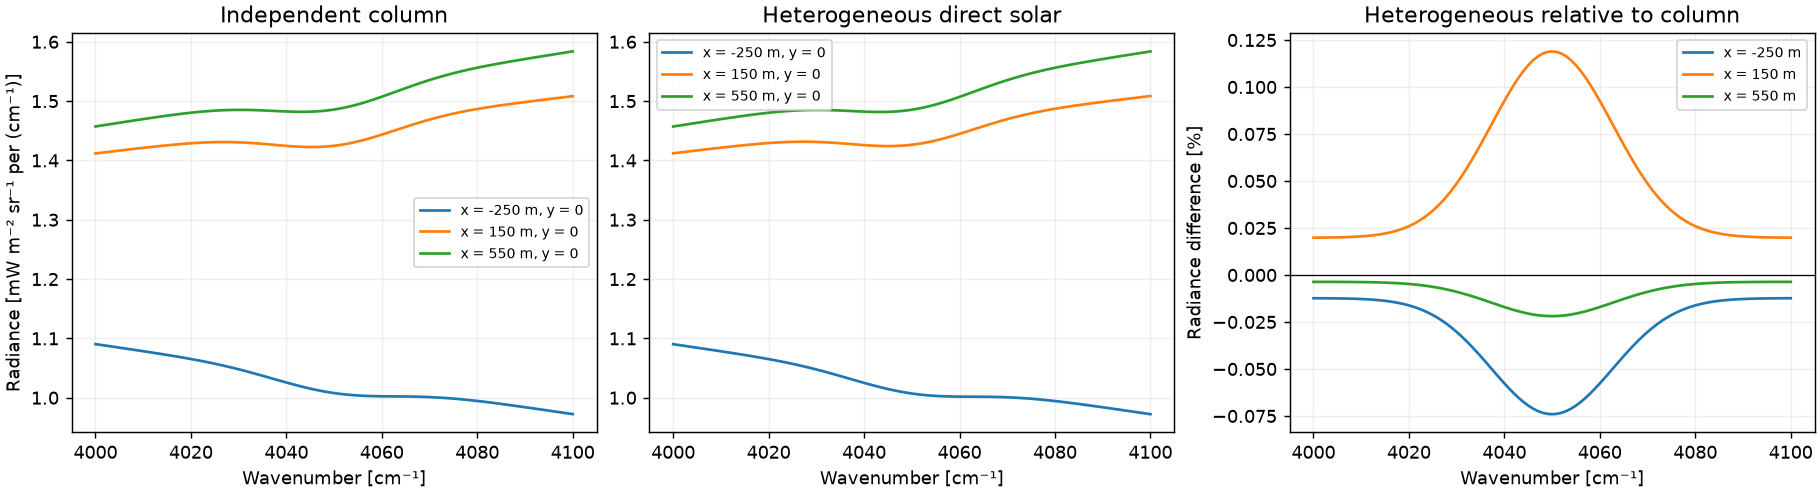

In [6]:
positions = np.array([[-250.0, 0.0], [150.0, 0.0], [550.0, 0.0]])
times = np.zeros(3)
directions = np.broadcast_to(view_local, (3, 3))  # Outward chart-local views.
modes = ("independent_column", "heterogeneous_direct_solar")
mode_labels = ("Independent column", "Heterogeneous direct solar")
point_spectra = {}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), layout="constrained")
axes[1].sharey(axes[0])
for ax, mode, label in zip(axes[:2], modes, mode_labels, strict=True):
    model = scene.SyntheticRadianceModel(
        mode=mode, inputs=inputs, plume_amplitude=1.0, reflectance_offset=0.0,
    )
    values = model.radiance(positions, directions, times, wavenumber_grid(points))
    point_spectra[mode] = values
    for xy, value in zip(positions, values, strict=True):
        ax.plot(points, value * 1e3, label=f"x = {xy[0]:.0f} m, y = 0")
    ax.set(title=label, xlabel="Wavenumber [cm⁻¹]")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Radiance [mW m⁻² sr⁻¹ per (cm⁻¹)]")
mode_difference = 100 * (point_spectra[modes[1]] / point_spectra[modes[0]] - 1)
for xy, difference in zip(positions, mode_difference, strict=True):
    axes[2].plot(points, difference, label=f"x = {xy[0]:.0f} m")
axes[2].axhline(0, color="black", linewidth=0.7)
axes[2].set(title="Heterogeneous relative to column",
            xlabel="Wavenumber [cm⁻¹]", ylabel="Radiance difference [%]")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.2)
show_figure(fig)

### Change the physical values before differentiating

`plume_amplitude` is a nonnegative dimensionless multiplier of plume excess; amplitude zero retains background gas. `reflectance_offset` is an additive dimensionless shift of the whole reflectance law. Each curve below constructs a model with one changed parameter at `x = 150 m, y = 0`. Gas abundance changes absorption; reflectance scales the direct surface source. The left panel resolves the small gas effect as a percentage change from amplitude one. The right panel shows absolute radiance.

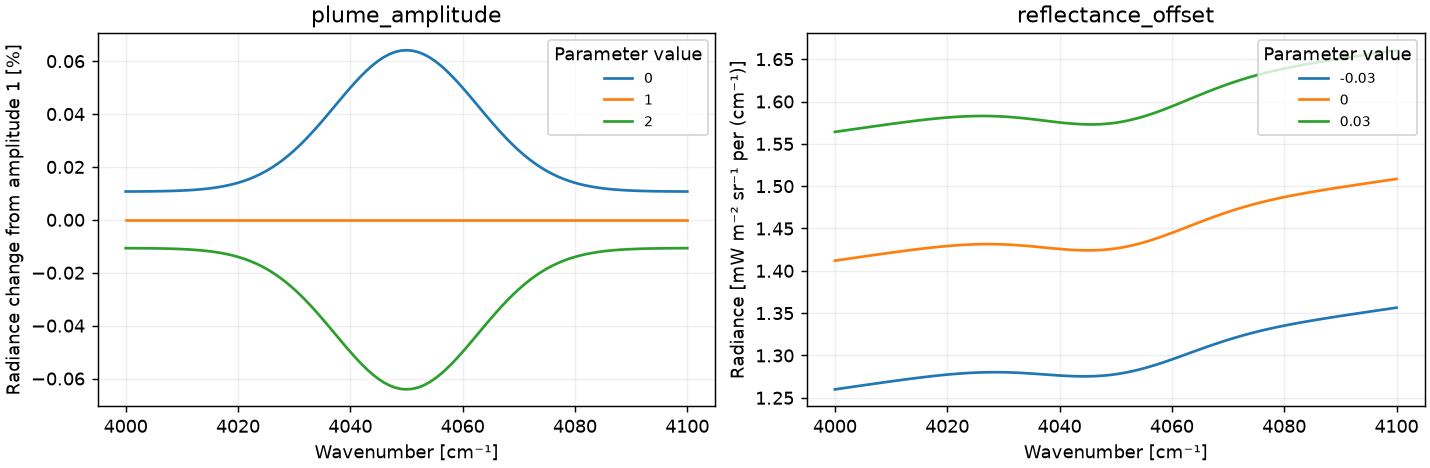

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for ax, parameter, choices in (
    (axes[0], "plume_amplitude", (0.0, 1.0, 2.0)),
    (axes[1], "reflectance_offset", (-0.03, 0.0, 0.03)),
):
    for choice in choices:
        parameters = dict(plume_amplitude=1.0, reflectance_offset=0.0)
        parameters[parameter] = choice
        model = scene.SyntheticRadianceModel(
            mode="heterogeneous_direct_solar", inputs=inputs, **parameters,
        )
        values = model.radiance(positions[1:2], directions[1:2], times[1:2], wavenumber_grid(points))[0]
        plotted = (100 * (values / point_spectra[modes[1]][1] - 1)
                   if parameter == "plume_amplitude" else values * 1e3)
        ax.plot(points, plotted, label=f"{choice:g}")
    ax.set(title=parameter, xlabel="Wavenumber [cm⁻¹]")
    ax.legend(title="Parameter value", fontsize=8)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Radiance change from amplitude 1 [%]")
axes[1].set_ylabel("Radiance [mW m⁻² sr⁻¹ per (cm⁻¹)]")
show_figure(fig)

### Tilt the terrain with a fresh fixture

Terrain affects path start heights and the surface normal. The example below uses slopes `(0.02, -0.01)` and prints the changed surface height and solar incidence at `x = 150 m`. Heterogeneous direct solar supports this affine terrain. The independent-column binding rejects nonzero slopes. The connected camera certificate additionally requires slope norm at most `0.1` and atmospheric edges within `[0, 1500] m`.

The separate `SplineTerrain` illustration binds a sampled grid, its closed domain and both height derivatives to one cubic interpolant. It is application-owned support. This curved surface is evaluated independently; the connected camera and its coverage proof keep their affine terrain. Full-ray visibility requires a separate policy.


In [8]:
sloped_inputs = scene.synthetic_inputs()
sloped_inputs["slopes"] = np.array([0.02, -0.01])
sloped_surface, sloped_normal = affine_surface_points(
    positions[1:2], height_m=sloped_inputs["height_m"], slopes=sloped_inputs["slopes"],
)
sloped_model = scene.SyntheticRadianceModel(
    mode="heterogeneous_direct_solar", inputs=sloped_inputs,
    plume_amplitude=1.0, reflectance_offset=0.0,
)
sloped_values = sloped_model.radiance(positions[1:2], directions[1:2], times[1:2], wavenumber_grid(small_points))
print("Sloped surface [m]:", sloped_surface)
print("Upward normal:", sloped_normal,
      "; Sun incidence cosine:", sloped_normal @ sloped_inputs["sun_direction"])
print("Sloped radiance at 4050 cm⁻¹:", sloped_values[0, 2], "W m⁻² sr⁻¹ per (cm⁻¹)")
try:
    scene.SyntheticRadianceModel(mode="independent_column", inputs=sloped_inputs,
                         plume_amplitude=1.0, reflectance_offset=0.0)
except ValueError as error:
    print("Expected independent-column rejection:", error)
else:
    raise AssertionError("Sloped independent columns must be rejected")
# Independent curved surface; do not feed it into the affine camera certificate.
terrain_x = np.linspace(-100.0, 100.0, 9)
terrain_y = np.linspace(-80.0, 80.0, 7)
terrain_xx, terrain_yy = np.meshgrid(terrain_x, terrain_y, indexing="ij")
terrain = SplineTerrain(terrain_x, terrain_y,
                        20 + 0.002 * terrain_xx**2 + 0.001 * terrain_yy**2)
np.testing.assert_allclose(terrain.height(np.array([30.0, -20.0])), 22.2)
np.testing.assert_allclose(terrain.gradient(np.array([30.0, -20.0])), [0.12, -0.04])
assert terrain.horizontal_bounds_m == (-100, 100, -80, 80)


Sloped surface [m]: [[150.   0. 253.]]
Upward normal: [-0.019995    0.0099975   0.99975009] ; Sun incidence cosine: 0.7878030738442321
Sloped radiance at 4050 cm⁻¹: 0.0014047174437363077 W m⁻² sr⁻¹ per (cm⁻¹)
Expected independent-column rejection: independent columns require horizontal terrain


## 6. Sample the scene with a camera

`make_acquisition` supplies a two-row, two-column camera and two exposures: `[0, 0.04] s` and `[0.1, 0.14] s`. The sensor moves at `800 m/s` in chart x at height `5000 m`, with local oblique pointing `0.3 rad`. Projection uses the synthetic rotation to prepare chart coordinates and outward local views; it supplies no Earth-fixed transform or real orbit.

The camera uses 2 mm pitch/active size, 0.3 m focal length, f/4 optics, a 0.3 mm Gaussian point-spread function (PSF), and quantum efficiency `0.7`. Rows carry different synthetic filter strips, `b0` and `b1`. Each read integrates over exposure time, finite angular response and spectrum.

For a short interactive run, this notebook uses **angular order 5, time order 2 and 33 spectral nodes**. These are teaching quadratures, without a convergence claim. The support's `detector_prediction` default angular order is 21; [connected tests](../tests/test_spatial_scene.py) contain separate refinement evidence.

In [9]:
angular_order = 5
time_order = 2
spectral_count = 33
camera, grid, coverage = scene.make_acquisition(
    inputs, angular_order=angular_order, time_order=time_order,
)
spectral = wavenumber_grid(
    np.linspace(*inputs["spectral_interval"], spectral_count),
    domain=SpectralDomain("wavenumber_cm1", (inputs["spectral_interval"],)),
)
covered = coverage(grid, spectral)
assert covered.all()
print("Native image axes (frame, row, column):", grid.image_shape)
print("Chart sample axes (read, joint node, x/y):", grid.xy_m.shape)
print("Bands in flattened native-read order:", grid.read_bands)
print("Certified complete reads:", covered)

Native image axes (frame, row, column): (2, 2, 2)
Chart sample axes (read, joint node, x/y): (8, 50, 2)
Bands in flattened native-read order: ('b0', 'b0', 'b1', 'b1', 'b0', 'b0', 'b1', 'b1')
Certified complete reads: [ True  True  True  True  True  True  True  True]


The footprints below show quadrature nodes and conservative surface bounds, grouped by native read. A read's quadrature nodes are numerical integration samples within one measurement. Its footprint can overlap another read's footprint.

`coverage` is bound to the exact stable grid and its analytic laws. It checks full exposure intervals, declared spectral-domain edges, terrain, viewing cone, and displaced atmospheric-path support. The surface rectangles below show only one part of that proof. Sampled nodes alone do not certify continuous coverage. Rebuild the acquisition and certificate after changing geometry.

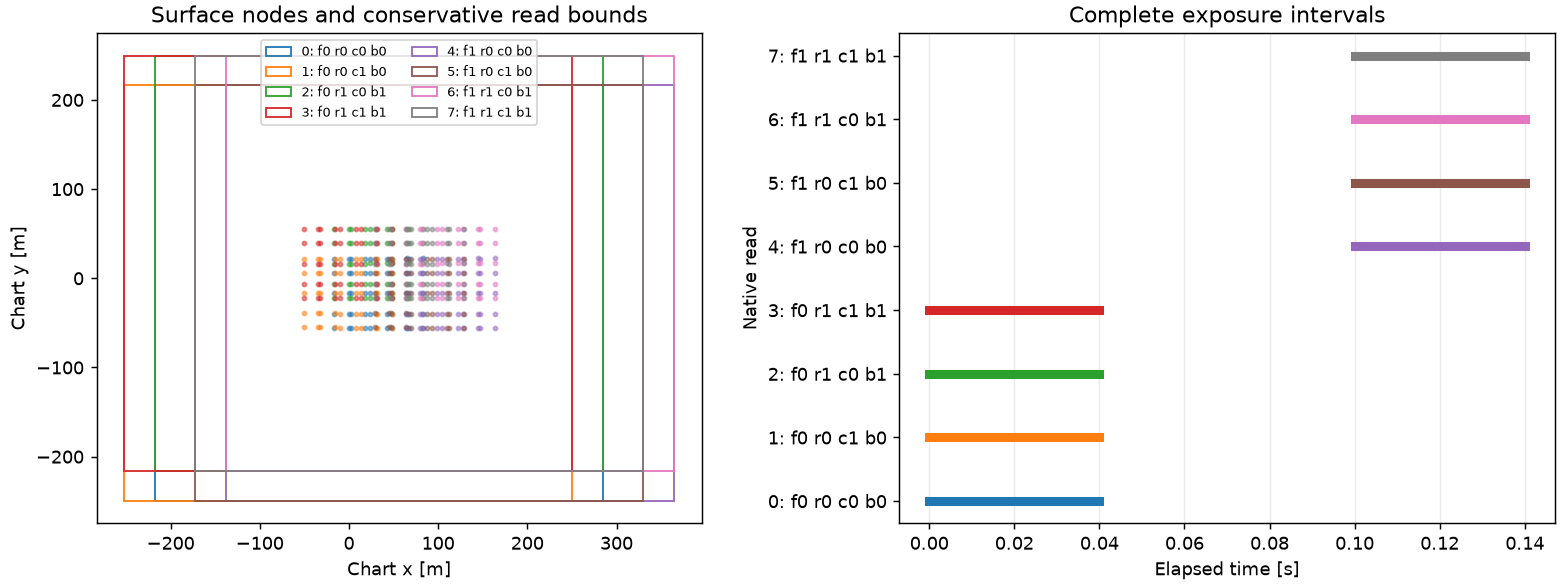

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
read_labels = []
for read, (xy, bounds, band, exposure) in enumerate(zip(
    grid.xy_m, grid.bounds_m, grid.read_bands,
    grid.schedule.reads.exposure_bounds_s, strict=True,
)):
    frame, row, column = np.unravel_index(read, grid.image_shape)
    label = f"{read}: f{frame} r{row} c{column} {band}"
    read_labels.append(label)
    color = f"C{read}"
    axes[0].scatter(xy[:, 0], xy[:, 1], s=5, color=color, alpha=0.5)
    axes[0].add_patch(Rectangle(
        (bounds[0], bounds[2]), bounds[1] - bounds[0], bounds[3] - bounds[2],
        fill=False, edgecolor=color, linewidth=1, label=label,
    ))
    axes[1].plot(exposure, [read, read], color=color, linewidth=5)
axes[0].set(xlabel="Chart x [m]", ylabel="Chart y [m]",
            title="Surface nodes and conservative read bounds")
axes[0].set_aspect("equal")
axes[0].legend(fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 1.0))
axes[1].set(xlabel="Elapsed time [s]", ylabel="Native read",
            title="Complete exposure intervals", yticks=np.arange(8), yticklabels=read_labels)
axes[1].grid(axis="x", alpha=0.25)
show_figure(fig)

In [11]:
# Identical samples in a different grid object do not carry this certificate.
assert not coverage(replace(grid), spectral).any()
wide_domain = wavenumber_grid(
    spectral.points, domain=SpectralDomain("wavenumber_cm1", ((3999.0, 4101.0),)),
)
assert not coverage(grid, wide_domain).any()
print("Copied grid rejected; wider declared spectrum rejected despite unchanged nodes.")

Copied grid rejected; wider declared spectrum rejected despite unchanged nodes.


## 7. Inspect native expected photoelectrons

`detector_prediction` calls `frame_electron_tangents` to integrate radiance and its physical directions with shared photon coefficients. Those coefficients include spatial, temporal and spectral quadrature, photon conversion, pupil/throughput and quantum efficiency.

The returned image shape is `(frame, detector_row, detector_column) = (2, 2, 2)`. The rows have different bands and the frames have different exposure times. These panels are native detector arrays, not common-band ground maps. No resampling, reconstruction or retrieval is performed. Values are expected photoelectrons, with no random noise draw or noisy digital-number image.

In [12]:
settings = dict(inputs=inputs, spectral_count=spectral_count,
                angular_order=angular_order, time_order=time_order, batch_size=4)
predictions = {}
jacobians = {}
for mode in modes:
    predictions[mode], jacobians[mode] = scene.detector_prediction(mode=mode, **settings)
    assert predictions[mode].shape == (2, 2, 2)
    assert jacobians[mode].shape == (2, 2, 2, 2)
print("Heterogeneous expected electrons:\n", predictions[modes[1]])
print("Jacobian axes: (frame, row, column, parameter):", jacobians[modes[1]].shape)

Heterogeneous expected electrons:
 [[[3.26741839e+09 3.13051603e+09]
  [3.26572251e+09 3.11977592e+09]]

 [[3.52071647e+09 3.42551900e+09]
  [3.53575807e+09 3.43426694e+09]]]
Jacobian axes: (frame, row, column, parameter): (2, 2, 2, 2)


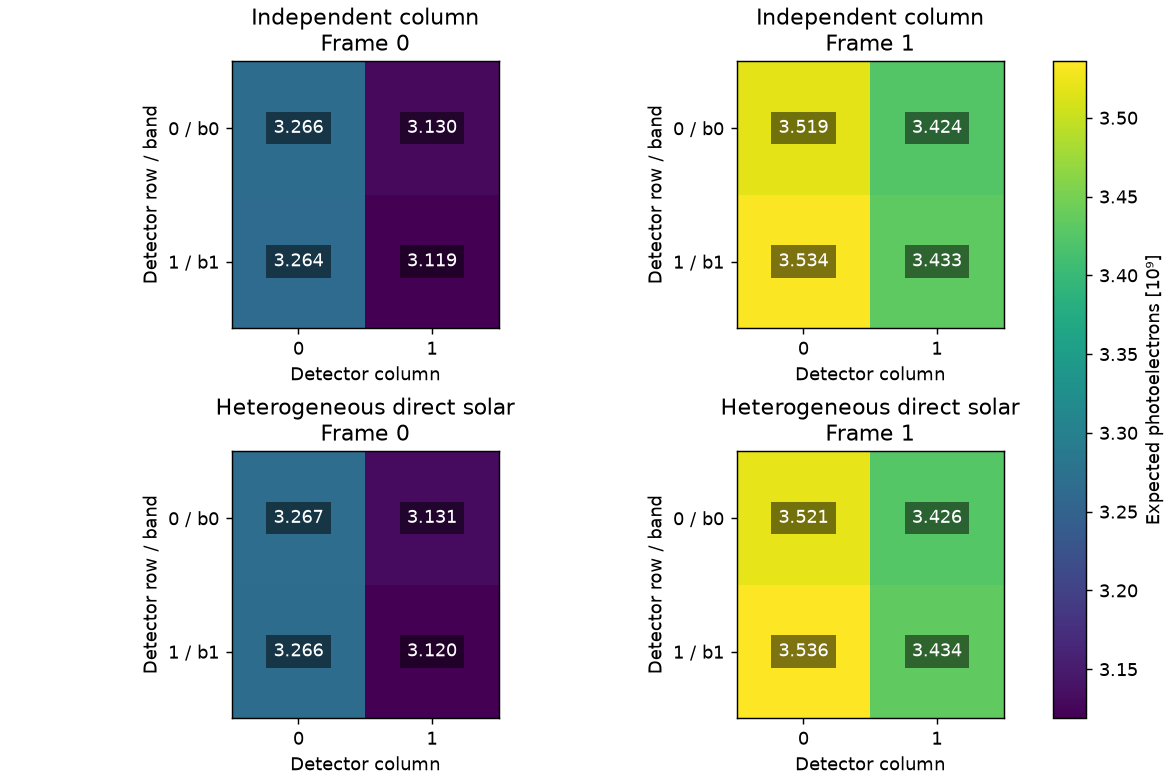

In [13]:
vmin = min(value.min() for value in predictions.values()) / 1e9
vmax = max(value.max() for value in predictions.values()) / 1e9
fig, axes = plt.subplots(2, 2, figsize=(9, 6), layout="constrained")
for row, (mode, label) in enumerate(zip(modes, mode_labels, strict=True)):
    for frame in range(2):
        ax = axes[row, frame]
        values = predictions[mode][frame] / 1e9
        image = ax.imshow(values, vmin=vmin, vmax=vmax, cmap="viridis")
        for (r, c), value in np.ndenumerate(values):
            ax.text(c, r, f"{value:.3f}", ha="center", va="center", color="white",
                    bbox=dict(facecolor="black", alpha=0.5, edgecolor="none"))
        ax.set(title=f"{label}\nFrame {frame}", xlabel="Detector column",
               ylabel="Detector row / band", xticks=[0, 1], yticks=[0, 1],
               yticklabels=["0 / b0", "1 / b1"])
fig.colorbar(image, ax=axes.ravel().tolist(), label="Expected photoelectrons [10⁹]")
show_figure(fig)

## 8. Read the two tangent axes

The last Jacobian axis gives derivatives per unit **dimensionless plume amplitude** (`k = 0`) and per unit **additive reflectance** (`k = 1`). Additional absorbing gas lowers direct radiance in this fixture; higher reflectance increases it.

The derivative boundary fixes the frozen puff shape and position, background, cross sections, irradiance, terrain, geometry, visibility and full instrument response. These are partial derivatives of expected electrons. They include neither transport/geometry derivatives nor noise draws, uncertainty propagation or an inverse estimate.

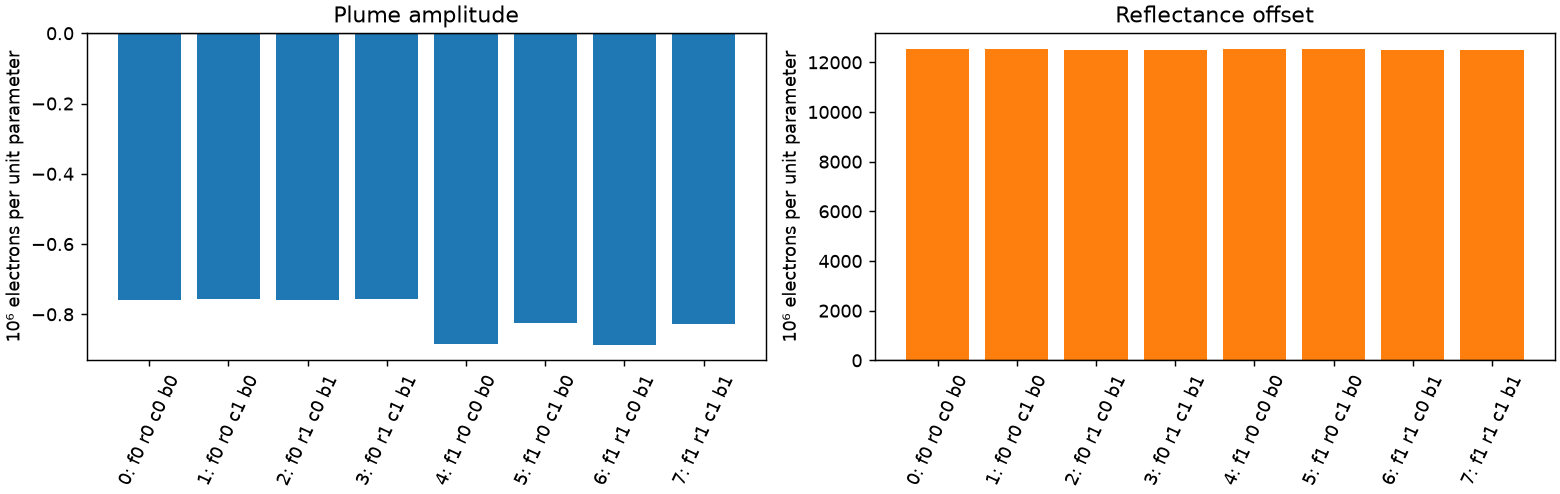

In [14]:
image = predictions[modes[1]]
jacobian = jacobians[modes[1]]
assert (jacobian[..., 0] < 0).all()
assert (jacobian[..., 1] > 0).all()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for k, (ax, parameter) in enumerate(zip(
    axes, ("Plume amplitude", "Reflectance offset"), strict=True,
)):
    ax.bar(np.arange(8), jacobian[..., k].ravel() / 1e6, color=f"C{k}")
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set(title=parameter, ylabel="10⁶ electrons per unit parameter",
           xticks=np.arange(8), xticklabels=read_labels)
    ax.tick_params(axis="x", labelrotation=65)
show_figure(fig)

### Check the derivative against a bounded finite difference

For each parameter `p`, compare the analytic Jacobian with `[F(p+h)-F(p-h)]/(2h)` at `h = 1e-3`. This requires four additional predictions on the same teaching quadrature. Geometry, cross sections and response stay fixed. The step keeps plume amplitude nonnegative and reflectance inside its supported interval.

The check uses the existing connected-test tolerance: relative `2e-7`, absolute `0.02 electron per unit parameter`. Agreement checks the derivative of this discrete forward calculation. It provides no independent physical validation or quadrature convergence evidence.

In [15]:
step = 1e-3
fd_errors = []
for k, parameter in enumerate(("plume_amplitude", "reflectance_offset")):
    centre = 1.0 if k == 0 else 0.0
    plus, _ = scene.detector_prediction(
        mode=modes[1], **settings, **{parameter: centre + step},
    )
    minus, _ = scene.detector_prediction(
        mode=modes[1], **settings, **{parameter: centre - step},
    )
    finite_difference = (plus - minus) / (2 * step)
    np.testing.assert_allclose(finite_difference, jacobian[..., k], rtol=2e-7, atol=0.02)
    relative_error = np.max(np.abs(finite_difference - jacobian[..., k]) /
                            np.maximum(np.abs(jacobian[..., k]), 1.0))
    fd_errors.append(relative_error)
    print(f"{parameter}: max scaled relative error = {relative_error:.3g}")
print(f"All notebook assertions passed; elapsed time {perf_counter() - started:.2f} s")

plume_amplitude: max scaled relative error = 1.05e-09
reflectance_offset: max scaled relative error = 7.86e-14
All notebook assertions passed; elapsed time 0.85 s


## 9. Keep the scope and function map nearby

| Question | Support function | Reused responsibility |
| --- | --- | --- |
| Which values define this example? | `synthetic_inputs` | Builds `LayerAtmosphere` and `GaussianPuffs`; owns all synthetic choices. |
| Which spectrum is assumed? | `synthetic_cross_section` | Owns the fixed illustrative cross section. |
| How does the chart rotate? | `chart_rotation` | Owns the analytic frame law used by trajectory, attitude and projection. |
| How much prescribed mass can lie outside support? | `plume_excluded_mass_bound` | Uses Gaussian half-space probabilities and a conservative union bound. |
| How do queries become radiance and tangents? | `SyntheticRadianceModel` | Scene gas conversion and direct/tangent transfer; application binding supplies physical fields and sampled time/spectral support. |
| What does the camera sample, and is the full read supported? | `make_acquisition` | Instruments acquisition and Geometry terrain intersection; owns the fixture-specific continuous coverage certificate. |
| What does the detector expect, and how does it change? | `detector_prediction` | Instruments simulation and joint response coefficients; returns native expected images and two parameter derivatives. |

**Limits of this support composition:** one non-water trace absorber, one frozen `GaussianPuffs` field, synthetic layer-independent cross sections, affine terrain, two scalar parameter directions and a small synthetic camera. The default field contains one puff; a supplied field can contain multiple puffs. Continuous coverage uses this camera's exact analytic laws and restricted geometry. Inputs must remain stable after binding.

**Broader library contracts:** Scene can compose multiple species/plumes and arbitrary signed parameter directions. Heterogeneous Scene transfer also accepts height/gradient callables with an explicit full-ray visibility policy. These capabilities do not extend this fixture's coverage certificate automatically. `surface_radiance` supplies the direct branch of this fixture.

**Physics and products outside this example:** diffuse or multiple scattering, thermal emission, terrain-aware plume transport, terrain-to-terrain light exchange, refraction, authentic spectroscopy, real orbital/Earth-frame support, retrieval and reconstruction. Other Orsia libraries contain some separate capabilities under their own contracts. The saved notebook outputs establish executable local behavior for these inputs, without geophysical-product or engineering qualification.

### Small edit-and-rerun exercises

1. Set `reflectance_contrast` to zero in the fixture cell before binding; rerun downstream cells. Compare the position-dependent spectra with the original curves.
2. Use plume amplitude zero in both mode calls in the point-spectra cell. Check whether the two modes agree for the horizontally uniform background at each position.
3. In the terrain example, change slopes to `(0.04, 0.0)`. Inspect the surface height and incidence; keep the independent-column rejection check.
4. Change `angular_order` from 5 to 13 in the acquisition cell and rerun downstream. Compare native expected electrons with the saved order-5 values. A single comparison is a sensitivity exercise; use the documented refinement protocol for a convergence assessment.
5. Change the finite-difference step to `1e-2`, then `1e-4`. Inspect the error for each parameter without changing the analytic Jacobian.

### Source trail

- [Terrain adapter](support/terrain.py): one interpolant, height and gradient methods, and a closed domain.
- [Support implementation](support/spatial_scene.py): the fixture and functions demonstrated here.
- [Spatial-scene guide](../docs/spatial-scenes.md): continuous coverage argument, derivative boundaries and existing evidence.
- [Scene public contracts](../libs/orsia-scene/README.md) and [composition functions](../libs/orsia-scene/src/orsia_scene/radiance.py): reusable behavior behind the support module.
- [Connected numerical tests](../tests/test_spatial_scene.py) and [this notebook's regression check](../tests/test_spatial_scene_notebook.py): distinct software evidence scopes.